# Diabetic Retinopathy using ResNet50

## 1. Import Library

In [1]:
import tensorflow as tf 
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
# Import họ ResNet V1 và hàm preprocess_input tương ứng
from tensorflow.keras.applications import ResNet101, ResNet152
from tensorflow.keras.applications.resnet import preprocess_input as preprocess_v1

# Import họ ResNet V2 và hàm preprocess_input tương ứng
from tensorflow.keras.applications import ResNet50V2, ResNet101V2, ResNet152V2
from tensorflow.keras.applications.resnet_v2 import preprocess_input as preprocess_v2

I0000 00:00:1784817598.992720    1489 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1784817600.603070    1489 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1784817642.424884    1489 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 2. Load Data 

In [2]:
BATCH_SIZE=4

In [3]:
with open("../../../data/processed/aptos/full_gaus/full_dataset.pkl", "rb") as f: #[cite: 1]
    data = pickle.load(f)

In [4]:
with open("../../../data/processed/aptos/test_images_gaus/sample_dataset.pkl", "rb") as f:
    data_test = pickle.load(f)

## 3. Data Preprocessing

In [5]:
X = data['data']
y = data['labels']
class_names = data['class_names']
NUM_CLASSES = len(class_names)
x_train, x_val, y_train, y_val = train_test_split(
    X,y, test_size=0.2, random_state=42, stratify=y
)
IMG_SIZE = x_train.shape[1]
print(f'Số mẫu: {len(y_train)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 2929 | Số lớp: 5 | Kích thước ảnh: 300x300


In [6]:
x_train

array([[[[124, 128, 128],
         [122, 128, 128],
         [129, 128, 128],
         ...,
         [134, 135, 133],
         [141, 141, 136],
         [139, 139, 134]],

        [[124, 128, 128],
         [122, 128, 128],
         [129, 128, 128],
         ...,
         [130, 132, 130],
         [135, 134, 131],
         [133, 133, 130]],

        [[124, 128, 128],
         [123, 128, 128],
         [130, 128, 128],
         ...,
         [128, 128, 127],
         [129, 128, 127],
         [128, 128, 127]],

        ...,

        [[130, 130, 130],
         [129, 129, 129],
         [129, 129, 129],
         ...,
         [128, 128, 128],
         [128, 128, 128],
         [128, 128, 128]],

        [[127, 127, 127],
         [128, 128, 128],
         [128, 128, 128],
         ...,
         [128, 128, 128],
         [128, 128, 128],
         [128, 128, 128]],

        [[128, 128, 128],
         [128, 128, 128],
         [128, 128, 128],
         ...,
         [127, 127, 127],
        

In [7]:
x_test = data_test['data']
y_test = data_test['labels']
print(f'Số mẫu: {len(y_test)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 366 | Số lớp: 5 | Kích thước ảnh: 300x300


In [8]:
y_train = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test  = tf.keras.utils.to_categorical(y_test,  NUM_CLASSES)
y_val = tf.keras.utils.to_categorical(y_val, NUM_CLASSES)

In [9]:
def preprocess_function_v1(image, label): 
    image = tf.cast(image, tf.float32)
    image = preprocess_v1(image)
    return image, label
def preprocess_function_v2(image, label): 
    image = tf.cast(image, tf.float32)
    image = preprocess_v2(image)
    return image, label

### Data train v1

In [10]:
# 3. KHỞI TẠO TẬP DATASET TRAIN
with tf.device('/CPU:0'):
    train_dataset_v1 = tf.data.Dataset.from_tensor_slices((x_train, y_train))
    # Áp dụng hàm tiền xử lý (map) và cho phép CPU tự động tối ưu luồng (AUTOTUNE)
    train_dataset_v1 = train_dataset_v1.map(preprocess_function_v1, num_parallel_calls=tf.data.AUTOTUNE)
    # Chia lô (batch) và nạp sẵn dữ liệu cho vòng lặp kế tiếp (prefetch) để tăng tốc GPU
    train_dataset_v1 = train_dataset_v1.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    test_dataset_v1 = tf.data.Dataset.from_tensor_slices((x_test, y_test))
    test_dataset_v1 = test_dataset_v1.map(preprocess_function_v1, num_parallel_calls=tf.data.AUTOTUNE)
    test_dataset_v1 = test_dataset_v1.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    val_dataset_v1 = tf.data.Dataset.from_tensor_slices((x_val, y_val))
    val_dataset_v1 = val_dataset_v1.map(preprocess_function_v1, num_parallel_calls=tf.data.AUTOTUNE)
    val_dataset_v1 = val_dataset_v1.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

I0000 00:00:1784817687.163402    1489 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1765 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


### Data train v2

In [11]:
# 3. KHỞI TẠO TẬP DATASET TRAIN
with tf.device('/CPU:0'):
    train_dataset_v2 = tf.data.Dataset.from_tensor_slices((x_train, y_train))
    # Áp dụng hàm tiền xử lý (map) và cho phép CPU tự động tối ưu luồng (AUTOTUNE)
    train_dataset_v2 = train_dataset_v2.map(preprocess_function_v2, num_parallel_calls=tf.data.AUTOTUNE)
    # Chia lô (batch) và nạp sẵn dữ liệu cho vòng lặp kế tiếp (prefetch) để tăng tốc GPU
    train_dataset_v2 = train_dataset_v2.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    test_dataset_v2 = tf.data.Dataset.from_tensor_slices((x_test, y_test))
    test_dataset_v2 = test_dataset_v2.map(preprocess_function_v2, num_parallel_calls=tf.data.AUTOTUNE)
    test_dataset_v2 = test_dataset_v2.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    val_dataset_v2 = tf.data.Dataset.from_tensor_slices((x_val, y_val))
    val_dataset_v2 = val_dataset_v2.map(preprocess_function_v2, num_parallel_calls=tf.data.AUTOTUNE)
    val_dataset_v2 = val_dataset_v2.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

### Ảnh tệp train 

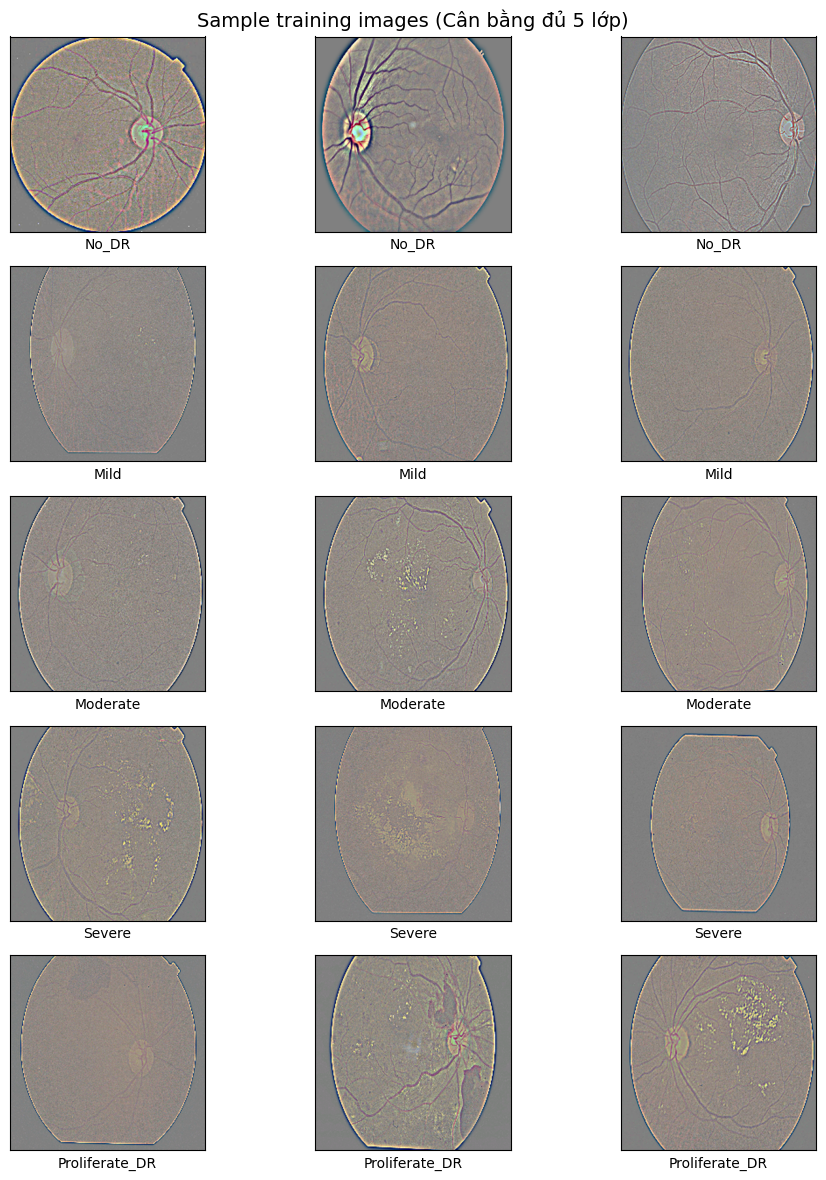

In [12]:
# 1. Chuyển y_train về dạng nhãn số 1D (nếu đang là One-hot encoding)
y_labels = np.argmax(y_train, axis=1) if len(y_train.shape) > 1 else y_train

num_classes = len(class_names)  # 5 lớp
samples_per_class = 3           # Số ảnh ngẫu nhiên lấy từ mỗi lớp (5 lớp x 3 = 15 ảnh)

plt.figure(figsize=(10, 12))

plot_idx = 1
for class_id in range(num_classes):
    # Lấy toàn bộ vị trí (index) của ảnh thuộc lớp class_id
    indices = np.where(y_labels == class_id)[0]
    
    # Chọn ngẫu nhiên N ảnh từ các vị trí đó
    selected_indices = np.random.choice(indices, samples_per_class, replace=False)
    
    for idx in selected_indices:
        plt.subplot(num_classes, samples_per_class, plot_idx)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(x_train[idx])
        plt.xlabel(class_names[class_id], fontsize=10)
        plot_idx += 1

plt.suptitle('Sample training images (Cân bằng đủ 5 lớp)', fontsize=14)
plt.tight_layout()
plt.show()

### Ảnh tệp test

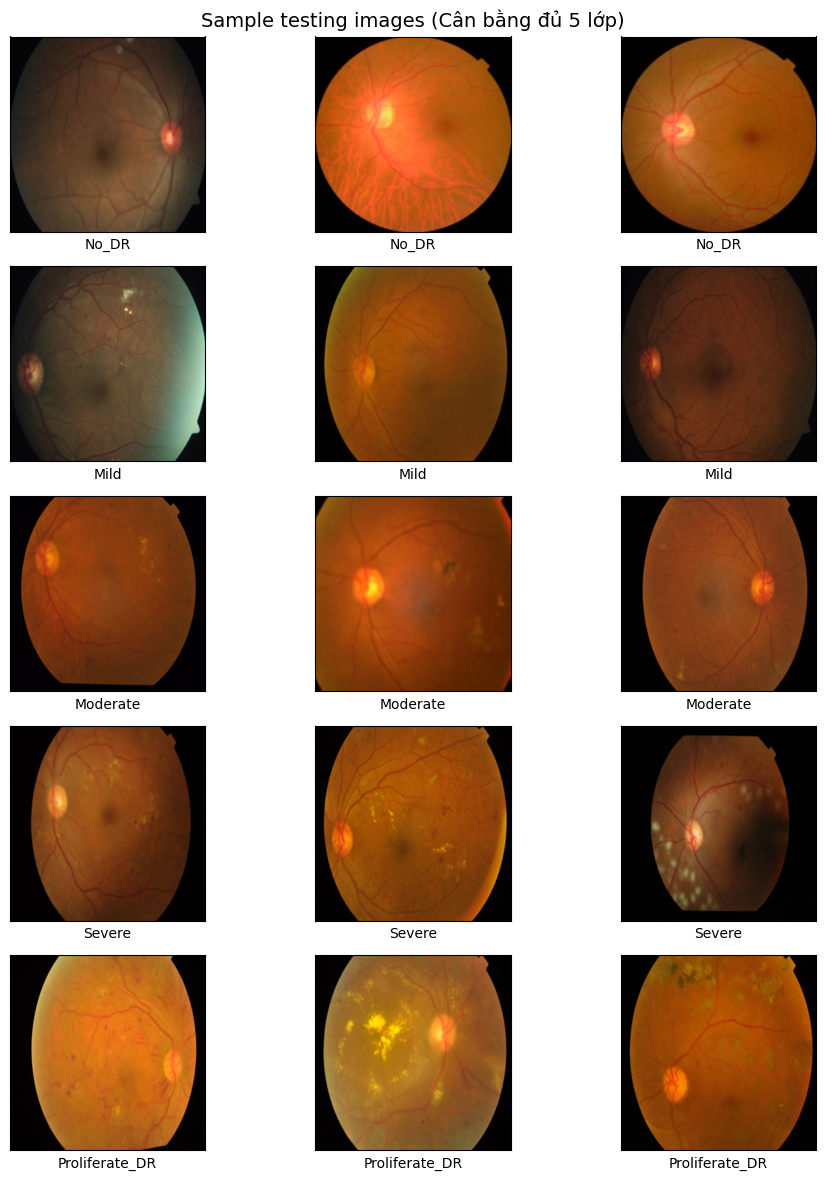

In [13]:
# 1. Chuyển y_train về dạng nhãn số 1D (nếu đang là One-hot encoding)
y_labels = np.argmax(y_test, axis=1) if len(y_test.shape) > 1 else y_test

num_classes = len(class_names)  # 5 lớp
samples_per_class = 3           # Số ảnh ngẫu nhiên lấy từ mỗi lớp (5 lớp x 3 = 15 ảnh)

plt.figure(figsize=(10, 12))

plot_idx = 1
for class_id in range(num_classes):
    # Lấy toàn bộ vị trí (index) của ảnh thuộc lớp class_id
    indices = np.where(y_labels == class_id)[0]
    
    # Chọn ngẫu nhiên N ảnh từ các vị trí đó
    selected_indices = np.random.choice(indices, samples_per_class, replace=False)
    
    for idx in selected_indices:
        plt.subplot(num_classes, samples_per_class, plot_idx)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(x_test[idx])
        plt.xlabel(class_names[class_id], fontsize=10)
        plot_idx += 1

plt.suptitle('Sample testing images (Cân bằng đủ 5 lớp)', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Xây dựng các model ResNet

In [14]:
def build_custom_resnet(base_model_class, input_shape, num_classes, model_names):
    """
    Hàm tổng quát để tạo model từ bất kỳ kiến trúc ResNet nào.
    Tham số base_model_class có thể là: ResNet101, ResNet152, ResNet50V2...
    """
    # Khởi tạo base model động
    base_model = base_model_class(weights='imagenet', 
                                  include_top=False, 
                                  input_shape=input_shape)
    
    # Đóng băng Base Model
    base_model.trainable = False
    
    # Xây dựng Classification Head (Phần đuôi phân loại)
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)
    
    x = Dense(512, activation='relu')(x)
    x = Dropout(0.5)(x) 
    x = BatchNormalization()(x)
    
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.5)(x)
    
    # Lớp phân loại 5 mức độ bệnh
    predictions = Dense(num_classes, activation='softmax')(x)
    
    model = Model(inputs=base_model.input, outputs=predictions, name=model_names)
    
    model.compile(optimizer=Adam(learning_rate=1e-4),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

### 4.1. Xây dựng model ResNet101

In [15]:
model_101 = build_custom_resnet(ResNet101, (IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES, 'ResNet101_Aptos_Gaus')
model_101.summary()

171446536/171446536 ━━━━━━━━━━━━━━━━━━━━ 64s 0us/step


Model: "ResNet101_Aptos_Gaus"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 306, 306,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 150, 150,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 150, 150,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 150, 150,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 152, 152,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 75, 75,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 75, 75,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 75, 75,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 75, 75,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 75, 75,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 75, 75,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 75, 75,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 75, 75,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 75, 75,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 75, 75,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 75, 75,    │      1,024 │ conv2_block1_3_c

 Total params: 43,850,117 (167.27 MB)

 Trainable params: 1,186,821 (4.53 MB)

 Non-trainable params: 42,663,296 (162.75 MB)

### 4.2 Xây dựng model ResNet152

In [16]:
model_152 = build_custom_resnet(ResNet152, (IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES, 'ResNet152_Aptos_Gaus')
model_152.summary()

234698864/234698864 ━━━━━━━━━━━━━━━━━━━━ 90s 0us/step


Model: "ResNet152_Aptos_Gaus"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 306, 306,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 150, 150,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 150, 150,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 150, 150,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 152, 152,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 75, 75,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 75, 75,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 75, 75,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 75, 75,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 75, 75,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 75, 75,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 75, 75,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 75, 75,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 75, 75,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 75, 75,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 75, 75,    │      1,024 │ conv2_block1_3_c

 Total params: 59,562,885 (227.21 MB)

 Trainable params: 1,186,821 (4.53 MB)

 Non-trainable params: 58,376,064 (222.69 MB)

### 4.3 Xây dựng model ResNet50V2 

In [17]:
model_50_V2 = build_custom_resnet(ResNet50V2, (IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES, 'ResNet50V2_Aptos_Gaus')
model_50_V2.summary()

94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 34s 0us/step


Model: "ResNet50V2_Aptos_Gaus"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 306, 306,  │          0 │ input_layer_2[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 150, 150,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 152, 152,  │          0 │ conv1_conv[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 75, 75,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 75, 75,    │        256 │ pool1_pool[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 75, 75,    │          0 │ conv2_block1_pre… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 75, 75,    │      4,096 │ conv2_block1_pre… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 75, 75,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 75, 75,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_pad  │ (None, 77, 77,    │          0 │ conv2_block1_1_r… │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 75, 75,    │     36,864 │ conv2_block1_2_p… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 75, 75,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 75, 75,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 75, 75,    │     16,640 │ conv2_block1_pre… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 75, 75,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_out    │ (None, 75, 75,    │          0 │ conv2_block1_0_c

 Total params: 24,756,741 (94.44 MB)

 Trainable params: 1,186,821 (4.53 MB)

 Non-trainable params: 23,569,920 (89.91 MB)

### 4.4 Xây dựng model ResNet101V2

In [18]:
model_101_V2 = build_custom_resnet(ResNet101V2, (IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES, 'ResNet101V2_Aptos_Gaus')
model_101_V2.summary()

171317808/171317808 ━━━━━━━━━━━━━━━━━━━━ 66s 0us/step


Model: "ResNet101V2_Aptos_Gaus"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 306, 306,  │          0 │ input_layer_3[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 150, 150,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 152, 152,  │          0 │ conv1_conv[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 75, 75,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 75, 75,    │        256 │ pool1_pool[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 75, 75,    │          0 │ conv2_block1_pre… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 75, 75,    │      4,096 │ conv2_block1_pre… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 75, 75,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 75, 75,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_pad  │ (None, 77, 77,    │          0 │ conv2_block1_1_r… │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 75, 75,    │     36,864 │ conv2_block1_2_p… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 75, 75,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 75, 75,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 75, 75,    │     16,640 │ conv2_block1_pre… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 75, 75,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_out    │ (None, 75, 75,    │          0 │ conv2_block1_0_c

 Total params: 43,818,501 (167.15 MB)

 Trainable params: 1,186,821 (4.53 MB)

 Non-trainable params: 42,631,680 (162.63 MB)

### 4.5 Xây dựng model ResNet152V2

In [19]:
model_152_V2 = build_custom_resnet(ResNet152V2, (IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES, 'ResNet152V2_Aptos_Gaus')
model_152_V2.summary()

234545216/234545216 ━━━━━━━━━━━━━━━━━━━━ 85s 0us/step


Model: "ResNet152V2_Aptos_Gaus"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 306, 306,  │          0 │ input_layer_4[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 150, 150,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 152, 152,  │          0 │ conv1_conv[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 75, 75,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 75, 75,    │        256 │ pool1_pool[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 75, 75,    │          0 │ conv2_block1_pre… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 75, 75,    │      4,096 │ conv2_block1_pre… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 75, 75,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 75, 75,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_pad  │ (None, 77, 77,    │          0 │ conv2_block1_1_r… │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 75, 75,    │     36,864 │ conv2_block1_2_p… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 75, 75,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 75, 75,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 75, 75,    │     16,640 │ conv2_block1_pre… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 75, 75,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_out    │ (None, 75, 75,    │          0 │ conv2_block1_0_c

 Total params: 59,523,589 (227.06 MB)

 Trainable params: 1,186,821 (4.53 MB)

 Non-trainable params: 58,336,768 (222.54 MB)

## 5. Compile & Train 

### 5.1 Compile & train ResNet101

In [20]:
model_101.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/resnet101_aptos_gaus_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=5, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=15, 
        restore_best_weights=True, verbose=1
    )
]
history_101 = model_101.fit(
    train_dataset_v1,
    epochs=100, 
    validation_data=val_dataset_v1,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1784818071.789156    2406 service.cc:153] XLA service 0x7f49400a1c70 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1784818071.789194    2406 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.5.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1784818072.339064    2406 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1784818076.057414    2406 cuda_dnn.cc:461] Loaded cuDNN version 92101
I0000 00:00:1784818076.470766    2406 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_43443__.351
I0000 00:00:1784818089.185509    2406 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.



Epoch 1: val_accuracy improved from None to 0.75034, saving model to ../../../data/models/resnet101_aptos_gaus_best.keras

Epoch 1: finished saving model to ../../../data/models/resnet101_aptos_gaus_best.keras
733/733 - 112s - 153ms/step - accuracy: 0.6227 - loss: 1.1230 - val_accuracy: 0.7503 - val_loss: 0.8761 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy improved from 0.75034 to 0.76398, saving model to ../../../data/models/resnet101_aptos_gaus_best.keras

Epoch 2: finished saving model to ../../../data/models/resnet101_aptos_gaus_best.keras
733/733 - 62s - 85ms/step - accuracy: 0.6753 - loss: 0.9522 - val_accuracy: 0.7640 - val_loss: 0.8148 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy improved from 0.76398 to 0.76808, saving model to ../../../data/models/resnet101_aptos_gaus_best.keras

Epoch 3: finished saving model to ../../../data/models/resnet101_aptos_gaus_best.keras
733/733 - 62s - 85ms/step - accuracy: 0.6883 - loss: 0.8779 - val_accuracy: 0.7681 

### 5.2 Compile & train ResNet152

In [21]:
model_152.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/resnet152_aptos_gaus_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=5, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=15, 
        restore_best_weights=True, verbose=1
    )
]
history_152 = model_152.fit(
    train_dataset_v1,
    epochs=100, 
    validation_data=val_dataset_v1,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1784819419.164613    2408 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_166312__.504



Epoch 1: val_accuracy improved from None to 0.75034, saving model to ../../../data/models/resnet152_aptos_gaus_best.keras

Epoch 1: finished saving model to ../../../data/models/resnet152_aptos_gaus_best.keras
733/733 - 141s - 193ms/step - accuracy: 0.6166 - loss: 1.1205 - val_accuracy: 0.7503 - val_loss: 0.9431 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy improved from 0.75034 to 0.75716, saving model to ../../../data/models/resnet152_aptos_gaus_best.keras

Epoch 2: finished saving model to ../../../data/models/resnet152_aptos_gaus_best.keras
733/733 - 87s - 119ms/step - accuracy: 0.6658 - loss: 0.9393 - val_accuracy: 0.7572 - val_loss: 0.8678 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy did not improve from 0.75716
733/733 - 83s - 113ms/step - accuracy: 0.6780 - loss: 0.8778 - val_accuracy: 0.7517 - val_loss: 0.8767 - learning_rate: 0.0010
Epoch 4/100

Epoch 4: val_accuracy did not improve from 0.75716
733/733 - 83s - 113ms/step - accuracy: 0.6968 - loss:

### 5.3 Compile & train ResNet50V2

In [22]:
model_50_V2.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/resnet50V2_aptos_gaus_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=5, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=15, 
        restore_best_weights=True, verbose=1
    )
]
history_50_V2 = model_50_V2.fit(
    train_dataset_v2,
    epochs=100, 
    validation_data=val_dataset_v2,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1784821377.434382    2405 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_293691__.182



Epoch 1: val_accuracy improved from None to 0.72988, saving model to ../../../data/models/resnet50V2_aptos_gaus_best.keras

Epoch 1: finished saving model to ../../../data/models/resnet50V2_aptos_gaus_best.keras
733/733 - 70s - 96ms/step - accuracy: 0.6115 - loss: 1.1514 - val_accuracy: 0.7299 - val_loss: 0.9197 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy improved from 0.72988 to 0.75034, saving model to ../../../data/models/resnet50V2_aptos_gaus_best.keras

Epoch 2: finished saving model to ../../../data/models/resnet50V2_aptos_gaus_best.keras
733/733 - 32s - 44ms/step - accuracy: 0.6640 - loss: 0.9656 - val_accuracy: 0.7503 - val_loss: 0.8645 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy did not improve from 0.75034
733/733 - 30s - 41ms/step - accuracy: 0.6849 - loss: 0.8710 - val_accuracy: 0.7408 - val_loss: 0.8748 - learning_rate: 0.0010
Epoch 4/100

Epoch 4: val_accuracy improved from 0.75034 to 0.75443, saving model to ../../../data/models/resnet50V2_

### 5.4 Compile & train ResNet101V2

In [23]:
model_101_V2.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/resnet101V2_aptos_gaus_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=5, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=15, 
        restore_best_weights=True, verbose=1
    )
]
history_101_V2 = model_101_V2.fit(
    train_dataset_v2,
    epochs=100, 
    validation_data=val_dataset_v2,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1784822032.403726    2407 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_392625__.301



Epoch 1: val_accuracy improved from None to 0.75989, saving model to ../../../data/models/resnet101V2_aptos_gaus_best.keras

Epoch 1: finished saving model to ../../../data/models/resnet101V2_aptos_gaus_best.keras
733/733 - 94s - 128ms/step - accuracy: 0.6186 - loss: 1.1265 - val_accuracy: 0.7599 - val_loss: 0.8847 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy did not improve from 0.75989
733/733 - 50s - 69ms/step - accuracy: 0.6582 - loss: 0.9539 - val_accuracy: 0.7599 - val_loss: 0.8418 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy did not improve from 0.75989
733/733 - 49s - 67ms/step - accuracy: 0.6859 - loss: 0.8944 - val_accuracy: 0.7572 - val_loss: 0.8119 - learning_rate: 0.0010
Epoch 4/100

Epoch 4: val_accuracy improved from 0.75989 to 0.76262, saving model to ../../../data/models/resnet101V2_aptos_gaus_best.keras

Epoch 4: finished saving model to ../../../data/models/resnet101V2_aptos_gaus_best.keras
733/733 - 53s - 73ms/step - accuracy: 0.6944 - l

### 5.5 Compile & train ResNet152V2

In [24]:
model_152_V2.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/resnet152V2_aptos_gaus_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=5, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=15, 
        restore_best_weights=True, verbose=1
    )
]
history_152_V2 = model_152_V2.fit(
    train_dataset_v2,
    epochs=100, 
    validation_data=val_dataset_v2,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1784823070.483280    2406 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_505211__.420



Epoch 1: val_accuracy improved from None to 0.73124, saving model to ../../../data/models/resnet152V2_aptos_gaus_best.keras

Epoch 1: finished saving model to ../../../data/models/resnet152V2_aptos_gaus_best.keras
733/733 - 168s - 229ms/step - accuracy: 0.6118 - loss: 1.1490 - val_accuracy: 0.7312 - val_loss: 0.8856 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy improved from 0.73124 to 0.75580, saving model to ../../../data/models/resnet152V2_aptos_gaus_best.keras

Epoch 2: finished saving model to ../../../data/models/resnet152V2_aptos_gaus_best.keras
733/733 - 119s - 162ms/step - accuracy: 0.6637 - loss: 0.9395 - val_accuracy: 0.7558 - val_loss: 0.8270 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy improved from 0.75580 to 0.75989, saving model to ../../../data/models/resnet152V2_aptos_gaus_best.keras

Epoch 3: finished saving model to ../../../data/models/resnet152V2_aptos_gaus_best.keras
733/733 - 121s - 164ms/step - accuracy: 0.6852 - loss: 0.8794 - val_a

## 6. Visualize Training

### 6.1 Visualize Training ResNet101

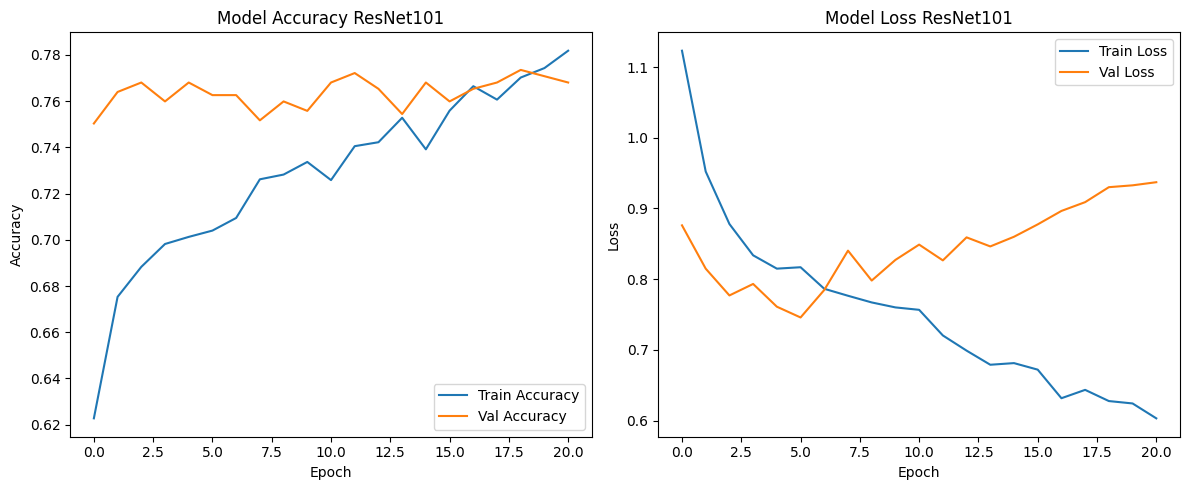

In [25]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_101.history['accuracy'], label='Train Accuracy')
plt.plot(history_101.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy ResNet101')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_101.history['loss'],     label='Train Loss')
plt.plot(history_101.history['val_loss'], label='Val Loss')
plt.title('Model Loss ResNet101')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

### 6.2 Visualize Training ResNet152

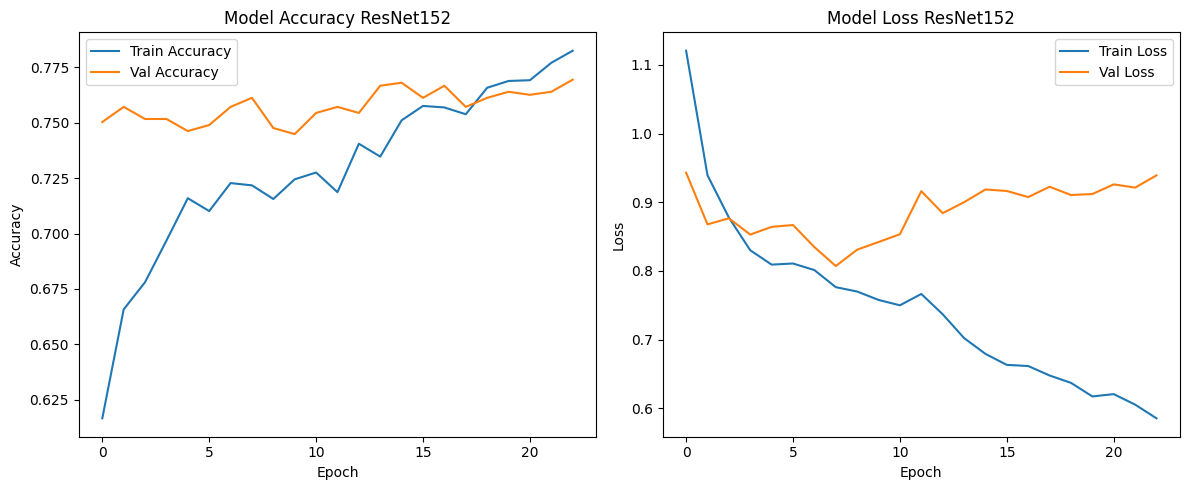

In [26]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_152.history['accuracy'], label='Train Accuracy')
plt.plot(history_152.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy ResNet152')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_152.history['loss'],     label='Train Loss')
plt.plot(history_152.history['val_loss'], label='Val Loss')
plt.title('Model Loss ResNet152')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

### 6.3 Visualize Training ResNet50V2

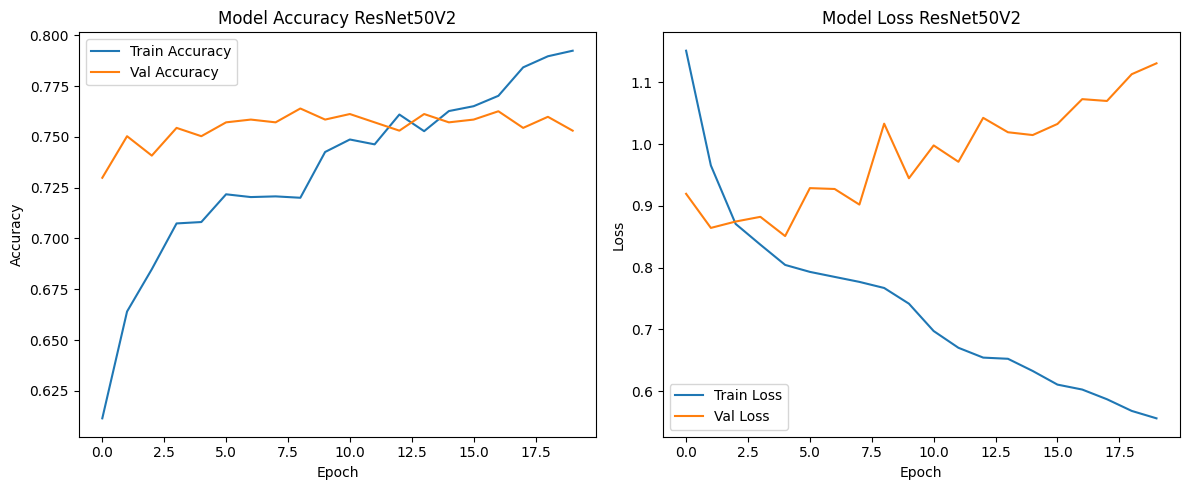

In [27]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_50_V2.history['accuracy'], label='Train Accuracy')
plt.plot(history_50_V2.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy ResNet50V2')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_50_V2.history['loss'],     label='Train Loss')
plt.plot(history_50_V2.history['val_loss'], label='Val Loss')
plt.title('Model Loss ResNet50V2')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

### 6.4 Visualize Training ResNet101V2

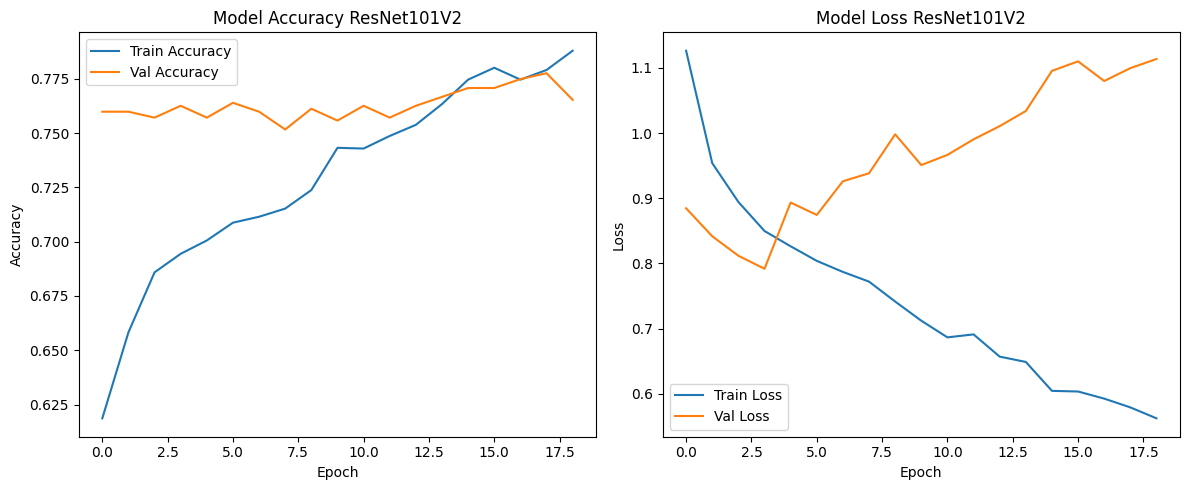

In [28]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_101_V2.history['accuracy'], label='Train Accuracy')
plt.plot(history_101_V2.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy ResNet101V2')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_101_V2.history['loss'],     label='Train Loss')
plt.plot(history_101_V2.history['val_loss'], label='Val Loss')
plt.title('Model Loss ResNet101V2')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

### 6.5 Visualize Training ResNet152V2 

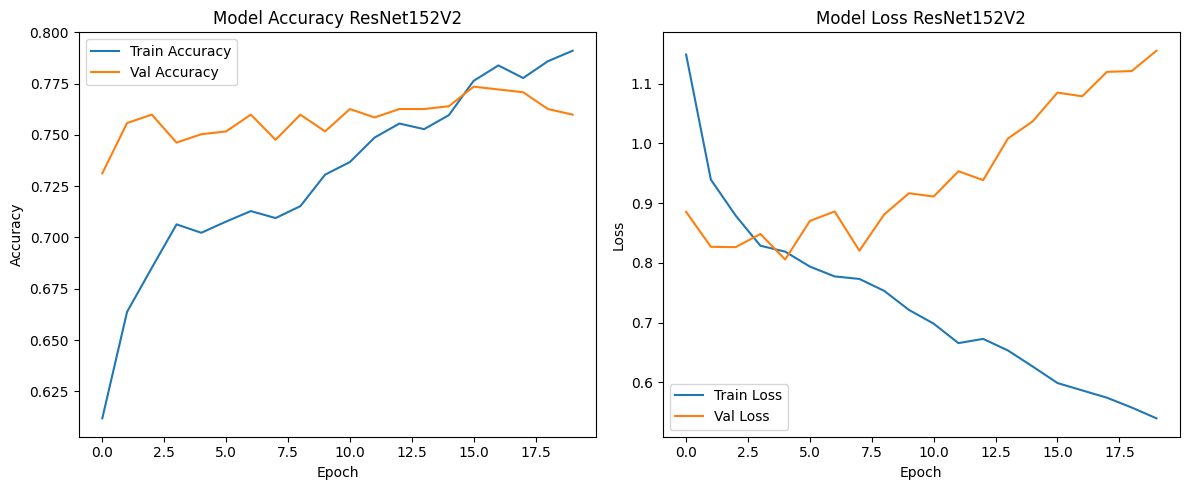

In [29]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_152_V2.history['accuracy'], label='Train Accuracy')
plt.plot(history_152_V2.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy ResNet152V2')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_152_V2.history['loss'],     label='Train Loss')
plt.plot(history_152_V2.history['val_loss'], label='Val Loss')
plt.title('Model Loss ResNet152V2')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

## 7. Evaluate on Test Set

In [30]:
test_loss_101, test_acc_101 = model_101.evaluate(test_dataset_v1, verbose=0)
print(f'Test Loss ResNet101: {test_loss_101:.4f}')
print(f'Test Accuracy ResNet101: {test_acc_101:.4f}') 

Test Loss ResNet101: 3.9026
Test Accuracy ResNet101: 0.5956


In [31]:
test_loss_152, test_acc_152 = model_152.evaluate(test_dataset_v1, verbose=0)
print(f'Test Loss ResNet101: {test_loss_152:.4f}')
print(f'Test Accuracy ResNet101: {test_acc_152:.4f}') 

Test Loss ResNet101: 4.4959
Test Accuracy ResNet101: 0.6940


In [32]:
test_loss_50V2, test_acc_50V2 = model_50_V2.evaluate(test_dataset_v2, verbose=0)
print(f'Test Loss ResNet50V2: {test_loss_50V2:.4f}')
print(f'Test Accuracy ResNet50V2: {test_acc_50V2:.4f}') 

Test Loss ResNet50V2: 4.5292
Test Accuracy ResNet50V2: 0.5710


In [33]:
test_loss_101V2, test_acc_101V2 = model_101_V2.evaluate(test_dataset_v2, verbose=0)
print(f'Test Loss ResNet101V2: {test_loss_101V2:.4f}')
print(f'Test Accuracy ResNet101V2: {test_acc_101V2:.4f}') 

Test Loss ResNet101V2: 5.0319
Test Accuracy ResNet101V2: 0.5792


In [34]:
test_loss_152V2, test_acc_152V2 = model_152_V2.evaluate(test_dataset_v2, verbose=0)
print(f'Test Loss ResNet152V2: {test_loss_152V2:.4f}')
print(f'Test Accuracy ResNet152V2: {test_acc_152V2:.4f}') 

Test Loss ResNet152V2: 6.9380
Test Accuracy ResNet152V2: 0.5519
